### 03 — Image Feature Extraction using EfficientNet-B0

What this notebook does:

- load the trained U-Net segmentation model
- load the validation-selected segmentation threshold
- freeze the U-Net during image feature extraction
- prepare grayscale ultrasound images for EfficientNet-B0
- load a pretrained EfficientNet-B0 backbone
- apply the predicted lesion mask to guide the visual feature map
- convert the EfficientNet feature map into visual tokens
- project the visual features to 768 dimensions
- test the full U-Net → EfficientNet image pipeline
- freeze the pretrained EfficientNet convolution layers before multimodal training.

The output from this notebook is a sequence of visual feature tokens that will later be combined with ClinicalBERT features in the multimodal fusion stage.


In [1]:
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image

from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

import sys
from pathlib import Path
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.unet import UNet
from src.dataset import BreastSegmentationDataset

### 1. Define Project Paths

The notebook uses the existing project folders for the raw ultrasound images, processed dataset splits, and trained model checkpoints.

The notebook also selects CUDA when a compatible GPU is available.


In [2]:
PROJECT_ROOT = Path("..")

DATA_DIR = PROJECT_ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"

IMAGE_DIR = RAW_DIR / "images"
MODEL_DIR = PROJECT_ROOT / "models"

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA GeForce GTX 1650


### 2. Load the Trained U-Net

The best U-Net checkpoint from the segmentation stage is loaded and set to evaluation mode.

This model is used to automatically generate the lesion mask required by the image encoder.


In [3]:
segmentation_model = UNet().to(device)

segmentation_model.load_state_dict(
    torch.load(
        MODEL_DIR / "best_unet.pth",
        map_location=device
    )
)

segmentation_model.eval()

print("U-Net loaded successfully")

U-Net loaded successfully


### 3. Load the Selected Segmentation Threshold

The threshold selected using the validation set in the segmentation notebook is loaded from segmentation_config.json.


In [4]:
import json

with open(
    MODEL_DIR / "segmentation_config.json",
    "r"
) as f:
    segmentation_config = json.load(f)

BEST_THRESHOLD = segmentation_config[
    "best_threshold"
]

print(
    "Loaded BEST_THRESHOLD:",
    BEST_THRESHOLD
)

Loaded BEST_THRESHOLD: 0.5499999999999999


### 4. Freeze the U-Net

The U-Net parameters are frozen. Here, U-Net is only used to generate predicted lesion masks and its weights are not updated.


In [5]:
for parameter in segmentation_model.parameters():
    parameter.requires_grad = False

### 5. Prepare Ultrasound Images for EfficientNet-B0

The ultrasound images are grayscale with one channel, while EfficientNet-B0 expects three-channel input.

The grayscale channel is repeated three times to produce an RGB-shaped tensor without changing the image information.


In [ ]:
def grayscale_to_rgb_tensor(image):
    """
    image shape:
        [B, 1, H, W]
    output:
        [B, 3, H, W]
    """
    return image.repeat(1, 3, 1, 1)

EfficientNet-B0 is initialised with ImageNet-pretrained weights, so the images are normalised using the ImageNet mean and standard deviation values.

In [7]:
weights = EfficientNet_B0_Weights.DEFAULT

mean = torch.tensor(
    [0.485, 0.456, 0.406],
    device=device
).view(1, 3, 1, 1)

std = torch.tensor(
    [0.229, 0.224, 0.225],
    device=device
).view(1, 3, 1, 1)

In [8]:
def normalize_for_efficientnet(image):
    return (image - mean) / std

### 6. Load Pretrained EfficientNet-B0

The model starts from ImageNet-pretrained weights so that the image branch benefits from previously learned visual representations rather than being trained completely from scratch.


In [9]:
efficientnet = efficientnet_b0(
    weights=EfficientNet_B0_Weights.DEFAULT
)

efficientnet = efficientnet.to(device)

### 7. Inspect the EfficientNet Feature Map

A dummy_image is passed through the EfficientNet feature extractor to confirm the output dimensions.

The final feature map contains 1280 channels and a reduced spatial resolution.


In [10]:
dummy_image = torch.randn(
    1, 3, 224, 224
).to(device)

with torch.no_grad():
    feature_map = efficientnet.features(dummy_image)

print(feature_map.shape)

torch.Size([1, 1280, 7, 7])


### 8. Apply Lesion-Guided Feature Weighting

The predicted U-Net mask is resized to the spatial dimensions of the EfficientNet feature map.

The mask is used to increase the contribution of features inside the predicted lesion region while preserving information from the surrounding breast tissue.

With alpha=1.0, lesion-region features receive additional weighting instead of removing the background completely.


In [11]:
def resize_mask_to_features(mask, feature_map):
    return F.interpolate(
        mask,
        size=feature_map.shape[-2:],
        mode="nearest"
    )

In [12]:
def apply_mask_guidance(feature_map, mask, alpha=1.0):
    small_mask = resize_mask_to_features(
        mask,
        feature_map
    )

    guided_features = feature_map * (
        1 + alpha * small_mask
    )

    return guided_features

### 9. Build the EfficientNet Image Encoder

The image encoder combines three operations:

1. extract the final EfficientNet convolutional feature map
2. apply lesion-mask guidance
3. flatten the spatial feature map into visual tokens and project each token from 1280 to 768 dimensions

The 768-dimensional output is to match the size used by ClinicalBERT, this makes the two modalities compatible for the later cross-attention stage.


In [ ]:
class EfficientNetEncoder(nn.Module):
    def __init__(self, output_dim=768):
        super().__init__()

        backbone = efficientnet_b0(
            weights=EfficientNet_B0_Weights.DEFAULT
        )

        self.features = backbone.features

        # EfficientNet-B0 output channels = 1280
        self.projection = nn.Linear(
            1280,
            output_dim
        )

    def forward(self, image, lesion_mask=None):

        feature_map = self.features(image)

        # lesion guidance
        if lesion_mask is not None:

            small_mask = F.interpolate(
                lesion_mask,
                size=feature_map.shape[-2:],
                mode="nearest"
            )

            feature_map = feature_map * (
                1.0 + small_mask
            )

        # [B, 1280, 7, 7]
        #        ↓
        # [B, 49, 1280]

        tokens = feature_map.flatten(2)
        tokens = tokens.transpose(1, 2)

        # Project 1280 → 768
        tokens = self.projection(tokens)

        return tokens

### 10. Test the Image Encoder

Verify the expected visual-token output shape before using real ultrasound images.


In [14]:
image_encoder = EfficientNetEncoder(
    output_dim=768
).to(device)

In [15]:
dummy_image = torch.randn(
    2, 3, 224, 224
).to(device)

dummy_mask = torch.ones(
    2, 1, 224, 224
).to(device)

visual_tokens = image_encoder(
    dummy_image,
    dummy_mask
)

print(visual_tokens.shape)

torch.Size([2, 49, 768])


### 11. Run a Real Ultrasound Image through U-Net and EfficientNet


In [16]:
val_df = pd.read_csv(
    PROCESSED_DIR / "val.csv"
)
IMAGE_SIZE = 224

val_dataset = BreastSegmentationDataset(
    val_df,
    IMAGE_DIR,
    IMAGE_SIZE
)

In [17]:
image, ground_truth_mask = val_dataset[0]

image = image.unsqueeze(0).to(device)

print(image.shape)

torch.Size([1, 1, 224, 224])


#### 11.1 Generate the Predicted Lesion Mask

The trained U-Net produces segmentation logits for the selected ultrasound image.

The BEST_THRESHOLD is then applied to convert the probability map into a binary predicted lesion mask.


In [18]:
with torch.no_grad():

    segmentation_logits = segmentation_model(image)

    predicted_mask = (
    torch.sigmoid(segmentation_logits)
    >= BEST_THRESHOLD
    ).float()

#### 11.2 Convert the Ultrasound Image for EfficientNet

The grayscale image is repeated for the three channels and normalised using the ImageNet statistics before being passed to EfficientNet-B0.


In [19]:
efficientnet_image = grayscale_to_rgb_tensor(
    image
)

efficientnet_image = normalize_for_efficientnet(
    efficientnet_image
)

#### 11.3 Extract Visual Tokens

The image and predicted lesion mask are passed into the EfficientNet encoder to extract the visual tokens


In [20]:
with torch.no_grad():

    visual_tokens = image_encoder(
        efficientnet_image,
        predicted_mask
    )

print("Visual features:", visual_tokens.shape)

Visual features: torch.Size([1, 49, 768])


### 12. Visualise the Segmentation Used for Image Guidance

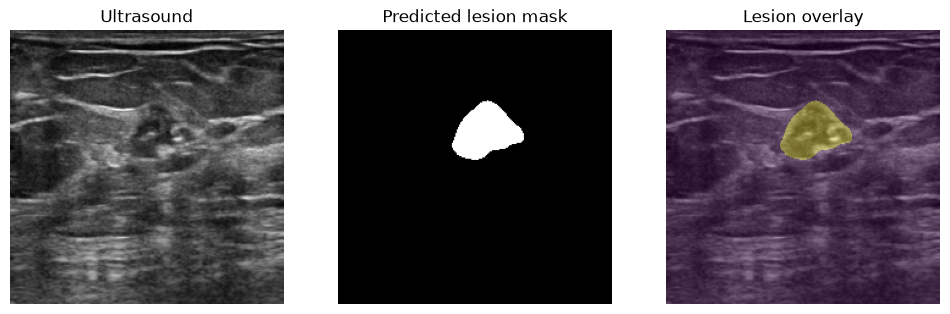

In [21]:
image_np = image.squeeze().cpu().numpy()
mask_np = predicted_mask.squeeze().cpu().numpy()

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(image_np, cmap="gray")
plt.title("Ultrasound")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask_np, cmap="gray")
plt.title("Predicted lesion mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(image_np, cmap="gray")
plt.imshow(mask_np, alpha=0.35)
plt.title("Lesion overlay")
plt.axis("off")

plt.show()

### 13. Freeze the Pretrained EfficientNet Layers

The pretrained EfficientNet convolutional layers are frozen before multimodal training.

This helps reduce overfitting on the relatively small dataset and lowers the number of parameters that need to be updated.

The final projection layer remains trainable so that the extracted visual features can adapt to the breast-ultrasound multimodal task.


In [22]:
for parameter in image_encoder.features.parameters():
    parameter.requires_grad = False

In [23]:
for parameter in image_encoder.projection.parameters():
    print(parameter.requires_grad)

True
True
